**Aim:** Identify cell types – cluster annotation 

**Tools**: 
- [`scanpy`](https://scanpy.readthedocs.io/en/stable/)

In [1]:
import os, sys
import pickle
import numpy as np 
import pandas as pd
from glob import glob

import scanpy as sc
import scanpy.external as sce
import anndata as ad
import scvi

import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import pyplot as plot
from matplotlib.backends.backend_pdf import PdfPages

sc.settings.verbosity = 1             # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.settings.set_figure_params(dpi=300,dpi_save=300, frameon=False, figsize=(5, 5), facecolor='white')

sc.logging.print_header()

scanpy==1.9.1 anndata==0.7.6 umap==0.5.1 numpy==1.20.3 scipy==1.7.1 pandas==1.3.3 scikit-learn==1.0 statsmodels==0.13.0 python-igraph==0.9.8 pynndescent==0.5.4


In [2]:
# https://stackoverflow.com/questions/21884271/warning-about-too-many-open-figures
plt.rcParams.update({'figure.max_open_warning': 0})

plt.close('all')

In [140]:
# https://stackoverflow.com/questions/3899980/how-to-change-the-font-size-on-a-matplotlib-plot

SMALL_SIZE = 6
MEDIUM_SIZE = 8
BIGGER_SIZE = 10

plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=SMALL_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title


In [4]:
from utils import *

Load filtered, normalized, and clustered `adata` files for all three conditions: 

In [5]:
MDMA  = sc.read_h5ad('celltyping/MDMA.h5ad.gz')
Meth  = sc.read_h5ad('celltyping/Meth.h5ad.gz')
Saline= sc.read_h5ad('celltyping/Saline.h5ad.gz')

Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


## Cluster and then annotate neuronal/non-neuronal cells
Ting's comments: 

In [6]:
cell_types = {
    "non-neuronal cells":[
        "Endothelial","Oligodentrocyte","oligodendrocyte progenitor cells (OPCs)",
        "Microglia","interneuron","astrocytes","neuroblast"
    ],

    "neuron":[
        "neuron main markers",
        "GABAergic",
        "glutamatergic",
        "D1 MSN",
        "D2 MSN (Ppp1r1b+ medial spiny neuron)",
        "D1H",
        "ICj"
    ]
}

marker_genes = {
    "oligodendrocyte progenitor cells (OPCs)":['Pdgfra'],
    "interneuron":["Resp18",'Lhx6','Zic1'],
    "Endothelial": ["Cldn5","Ptprb"], #"Ptgds"
    "Oligodentrocyte":["Mog",'Opalin'], # "Olig1",
    "Microglia":['C1qb','C1qa'], #"Cx3cr1",
    "astrocytes":["Aqp4",'Slc1a3','Gja1'],
    "neuroblast":["Top2a"],
    "neuron main markers":['Snap25','Zic2',#"Gria2", "Penk",'Dck','Nrxn1',"Nfasc","Kctd13",
                           "Sox11" #"Aplp1","Syt11","Slc2a1","Slc1a2","Slc4a4","Slc6a6","Qpct"
                          ],
    "GABAergic":["Gad1"],
    "glutamatergic":[
        "Slc17a7",
        "Gria1",
        "Gria2",
        "Grin1",
        "Grin3a",
        "Lrrtm2",
        "Slc1a1",
        "Slc1a2",
        "Slc6a13",
        "Slc7a11",
        "Slc17a6",
        "Slc17a6",
    ],
    "D1 MSN":['Tac1',"Pdyn"], # ,"Drd1a"
    "D2 MSN (Ppp1r1b+ medial spiny neuron)":["Penk","Drd2","Adora2a"],
    "D1H":["Nxph4","Tac2"],
    "ICj":["Crtac1","Rreb1"],
    "patch marker":["Sema5b"],
    "ventral striatum marker":["Crym"],
    "medial Shell":["Stard5","Stra6"]
}

In [7]:
neuron_genes = {
    cell_type: marker_genes[cell_type] 
    # gene 
    for cell_type in marker_genes 
    # for gene in marker_genes[cell_type] 
    if cell_type in cell_types['neuron']
}

not_neuron_genes = {
    cell_type: marker_genes[cell_type] 
    # gene 
    for cell_type in marker_genes 
    # for gene in marker_genes[cell_type] 
    if cell_type not in cell_types['neuron']
}

In [8]:
# pdf_pages = PdfPages(f'figures/violin_mitochondrial_{cond}.pdf')
# for col in [
#     'n_genes_by_counts','total_counts',
#     'pct_counts_mt'
# ]:
#     # Create a figure instance (ie. a new page)
#     fig = plot.figure(figsize=(12, 6), dpi=300)
#     # Plot whatever you wish to plot
#     print ('\033[1m' + col)
#     ax = plt.subplot()
#     sc.pl.violin(
#         adata, col, jitter=0.4, groupby='batch', 
#         multi_panel=True, ax=ax,rotation=90
#     )
#     # Done with the page
#     pdf_pages.savefig(fig,bbox_inches='tight')
# # Write the PDF document to the disk
# pdf_pages.close()

In [9]:
# writer = pd.ExcelWriter('cell-counts.xlsx', engine='xlsxwriter')
# # Write each dataframe to a different worksheet.
# pd.concat([
#     adata.obs.groupby('cond').size(),
#     adata_flt_mt.obs.groupby('cond').size(),
#     adata_flt_dd.obs.groupby('cond').size()
# ],axis=1).rename(columns={
#     0:'raw',1:'mt filtering',2:'doublet filtering'
# }).to_excel(writer,sheet_name='conditions')
# pd.concat([
#     adata.obs.groupby('batch').size(),
#     adata_flt_mt.obs.groupby('batch').size(),
#     adata_flt_dd.obs.groupby('batch').size()
# ],axis=1).rename(columns={
#     0:'raw',1:'mt filtering',2:'doublet filtering'
# }).to_excel(writer,sheet_name='batches')
# # Close the Pandas Excel writer and output the Excel file.
# writer.save()

In [10]:
def rank_genes_to_df(adata,n=50):
    result = adata.uns['rank_genes_groups']

    groups = result['names'].dtype.names

    df = pd.DataFrame(
        {group + '_' + key: result[key][group]
        for group in groups for key in ['names', 'scores']}).head(n)
    
    return df

### Meth

In [196]:
Meth.obs.groupby('batch').size()

batch
Meth_male_1    1742
Meth_male_2     823
Meth_male_3     425
dtype: int64

___
Add Snap25 marker labels

In [192]:
Meth_Snap25_df = pd.DataFrame(
    # Meth.layers['scaled'][:,Meth.var.index == 'Snap25'],
    Meth.X[:,Meth.var.index == 'Snap25'],
    columns=['Snap25'],index=Meth.to_df().index
)

Meth_Snap25_thr = Meth_Snap25_df.quantile(q=0.85).values[0]

In [160]:
Meth.obs['marker'] = ''
Meth.obs.loc[Meth.to_df().loc[:,'Snap25'] < Meth_Snap25_thr, 'marker'] = 'Snap25-'
Meth.obs.loc[Meth.to_df().loc[:,'Snap25'] >= Meth_Snap25_thr, 'marker'] = 'Snap25+'

In [198]:
Meth.obs.groupby('marker').size()

marker
Snap25+     449
Snap25-    2541
dtype: int64

___
Ting:
    
    Meth:
    Endothelial: 19, 3, 1, 10
    Oligodendrocytes: 2, 8
    Microglia: 5, 15, 9, 12
    Astrocytes: 17, 11
    Neurons: 16, 7, 13, 4, 18, 0, 14


In [11]:
leiden_list = []
for l in Meth.obs.leiden:
    if int(l) in [19, 3, 1, 10]: leiden_list.append('Endothelial')
    elif int(l) in [2, 8]: leiden_list.append('Oligodendrocytes')
    elif int(l) in [5, 15, 9, 12]: leiden_list.append('Microglia')
    elif int(l) in [17, 11]: leiden_list.append('Astrocytes')
    elif int(l) in [16, 7, 13, 4, 18, 0, 14]: leiden_list.append('Neurons')
    else: leiden_list.append(l)
len (leiden_list) == len(Meth.obs.leiden)

True

In [12]:
Meth.obs['label'] = pd.Categorical(leiden_list)

In [13]:
pd.DataFrame(
    Meth.obs.groupby(['label']).size() / Meth.obs.shape[0] * 100, columns=['%']).round(2)

,%
label,
6,4.21
Astrocytes,4.21
Endothelial,29.63
Microglia,12.21
Neurons,35.12
Oligodendrocytes,14.62


In [14]:
sc.tl.dendrogram(Meth,groupby='label')

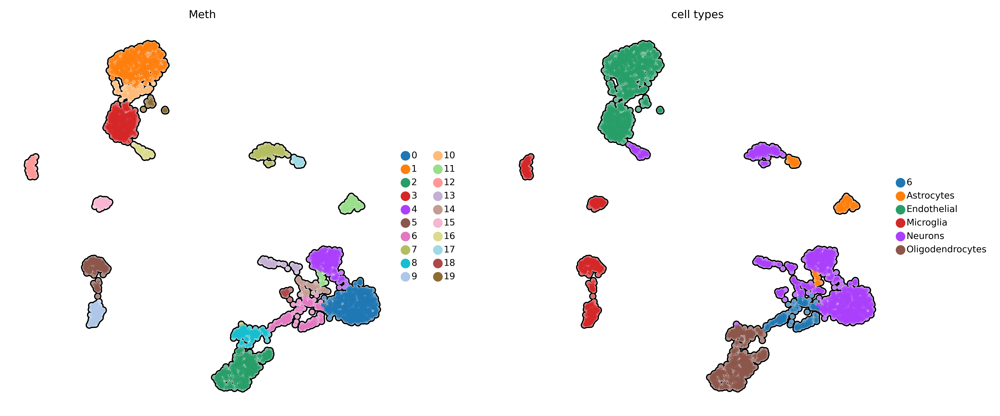

In [15]:
sc.pl.umap(
    Meth, 
    color=['leiden','label'],#'batch'],
    title=['Meth','cell types'],
    legend_fontsize='small',
    # vmin=-2,vmax=2, cmap='bwr', 
    layer='scaled',
    size=40, hspace=2,
    # save='tdT.pdf'
    add_outline=1
)

# !mv figures/umaptdT.pdf figures/tdT_umap_Meth.pdf

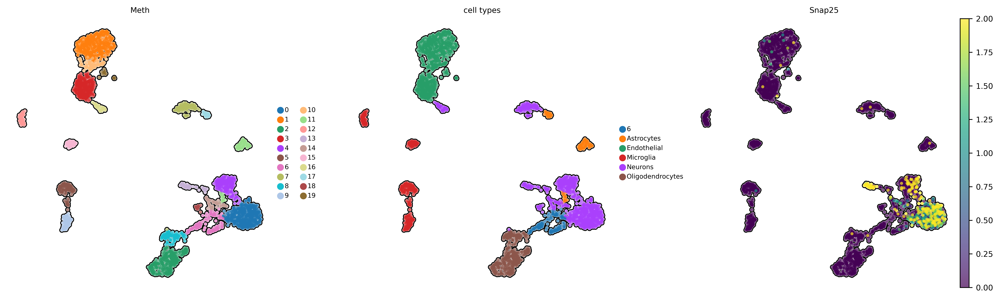

In [17]:
sc.pl.umap(
    Meth, 
    color=['leiden','label','Snap25'],
    title=['Meth','cell types'],
    legend_fontsize='small',
    vmin=0,vmax=2,
    # cmap='bwr', 
    layer='scaled',
    size=40, hspace=2,
    # save='tdT.pdf'
    add_outline=1
)

# !mv figures/umaptdT.pdf figures/tdT_umap_Meth.pdf

### MDMA

___
Ting:

    Endothelial: 15, 9, 7
    Oligodendrocytes: 2, 22, 17, 1, 6, 12
    Microglia: 18, 5, 11
    Astrocytes: 10, 20, 25
    Neurons, 8, 21, 13, 0, 3, 4, 24, 19, 23, 14, 16


In [53]:
leiden_list = []
for l in MDMA.obs.leiden:
    if int(l) in [15,9,7]: leiden_list.append('Endothelial')
    elif int(l) in [2, 22, 17, 1, 6, 12]: leiden_list.append('Oligodendrocytes')
    elif int(l) in [18, 5, 11]: leiden_list.append('Microglia')
    elif int(l) in [10, 20, 25]: leiden_list.append('Astrocytes')
    elif int(l) in [8, 21, 13, 0, 3, 4, 24, 19, 23, 14, 16]: leiden_list.append('Neurons')
    else: leiden_list.append(l)
len (leiden_list) == len(MDMA.obs.leiden)

True

In [54]:
MDMA.obs['label'] = pd.Categorical(leiden_list)

In [55]:
pd.DataFrame(
    MDMA.obs.groupby(['label']).size() / MDMA.obs.shape[0] * 100, columns=['%']).round(2)

,%
label,
Astrocytes,4.55
Endothelial,10.44
Microglia,8.93
Neurons,45.25
Oligodendrocytes,30.83


In [56]:
sc.tl.dendrogram(MDMA,groupby='label')

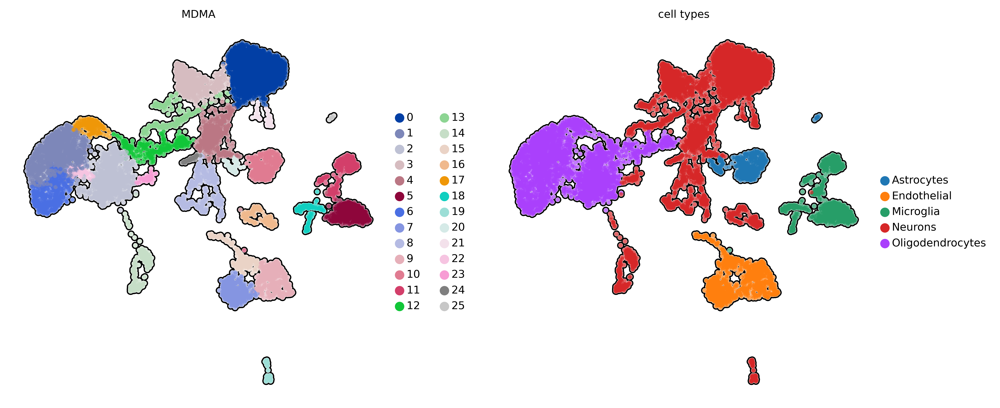

In [40]:
sc.pl.umap(
    MDMA, 
    color=['leiden','label'],#,'batch'],
    title=['MDMA','cell types'],
    legend_fontsize='medium',
    # vmin=-2,vmax=2, cmap='bwr', 
    layer='scaled',
    size=40, hspace=2,
    # save='tdT.pdf'
    add_outline=1
)

### Saline

___
Ting:

    dead cells: 23, 0, 2, 4
    Endothelial: 3, 1, 11, 15
    Oligodendrocytes: 13, 7, 8
    Microglia: 17, 22, 18, 5, 12
    Astrocytes: 20, 24, 14
    Neurons: 21, 9, 6, 16, 10, 19


In [203]:
leiden_list = []
for l in Saline.obs.leiden:
    if int(l) in [23, 0, 2, 4]: leiden_list.append('dead cells')
    elif int(l) in [3, 1, 11, 15]: leiden_list.append('Endothelial')
    elif int(l) in [13, 7, 8]: leiden_list.append('Oligodendrocytes')
    elif int(l) in [17, 22, 18, 5, 12]: leiden_list.append('Microglia')
    elif int(l) in [20, 24, 14]: leiden_list.append('Astrocytes')
    elif int(l) in [21, 9, 6, 16, 10, 19]: leiden_list.append('Neurons')
    else: leiden_list.append(l)
len (leiden_list) == len(Saline.obs.leiden)

True

In [204]:
Saline.obs['label'] = pd.Categorical(leiden_list)

In [205]:
pd.DataFrame(
    Saline.obs.groupby(['label']).size() / Saline.obs.shape[0] * 100, columns=['%']
).round(2)

,%
label,
Astrocytes,3.16
Endothelial,23.80
Microglia,9.96
Neurons,14.22
Oligodendrocytes,9.49
dead cells,39.37


In [206]:
pd.DataFrame(
    Saline.obs.loc[Saline.obs.label != 'dead cells',].groupby(['label']).size() / 
    Saline.obs.loc[Saline.obs.label != 'dead cells',].shape[0] * 100, columns=['%']
).round(2)

,%
label,
Astrocytes,5.21
Endothelial,39.25
Microglia,16.43
Neurons,23.46
Oligodendrocytes,15.66
dead cells,0.00


In [207]:
sc.tl.dendrogram(Saline,groupby='label')

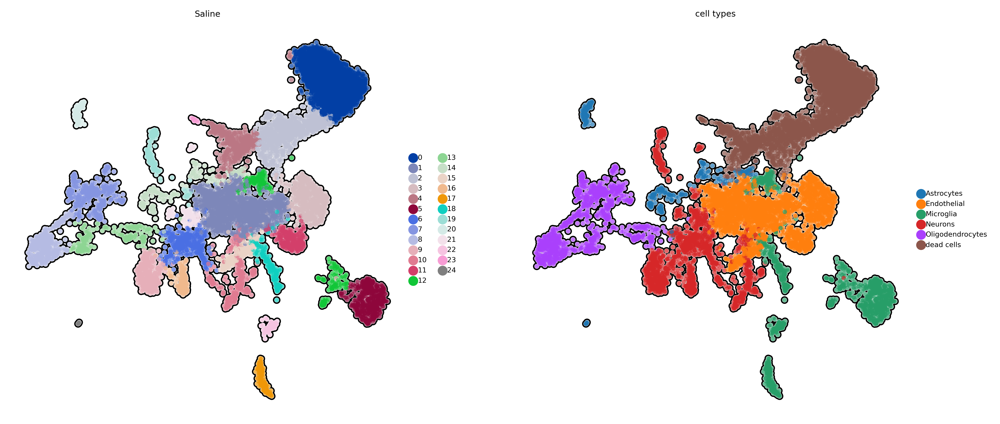

In [208]:
sc.pl.umap(
    Saline,#[Saline.obs.label != 'dead cells'], 
    color=['leiden','label'],#,'batch'],
    title=['Saline','cell types'],
    legend_fontsize='small',
    # vmin=-2,vmax=2, cmap='bwr', 
    layer='scaled',
    size=40, hspace=2,
    # save='tdT.pdf'
    add_outline=1
)

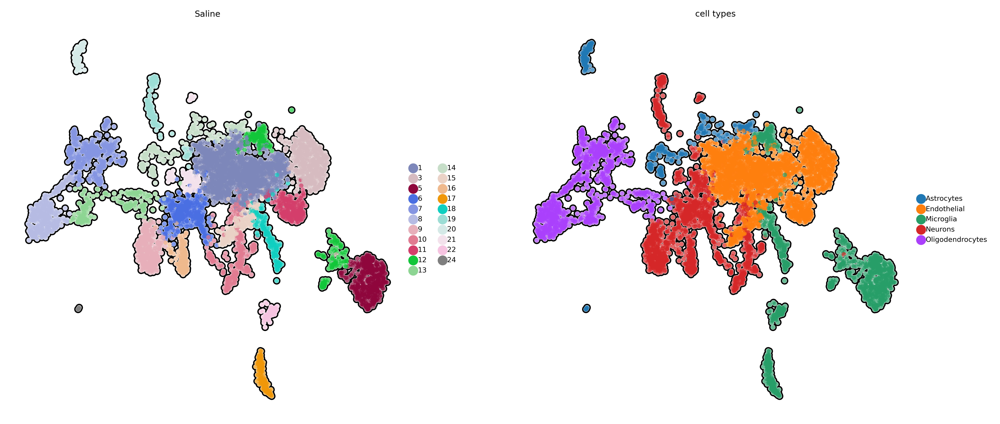

In [209]:
sc.pl.umap(
    Saline[Saline.obs.label != 'dead cells'], 
    color=['leiden','label'],#,'batch'],
    title=['Saline','cell types'],
    legend_fontsize='small',
    # vmin=-2,vmax=2, cmap='bwr', 
    layer='scaled',
    size=40, hspace=2,
    # save='tdT.pdf'
    add_outline=1
)

In [232]:
Saline_v2 = Saline[Saline.obs.label != 'dead cells'].copy()

Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


In [233]:
clustering(Saline_v2)

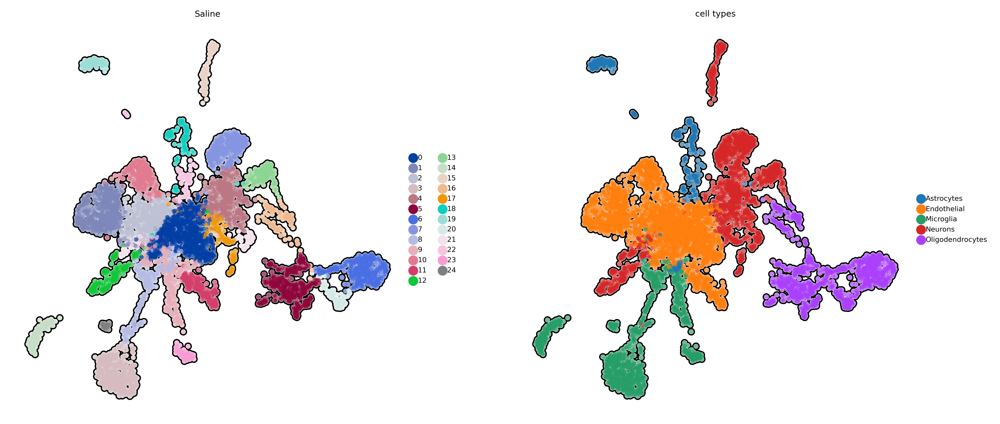

In [234]:
sc.pl.umap(
    Saline_v2,
    color=['leiden','label'],#,'batch'],
    title=['Saline','cell types'],
    legend_fontsize='small',
    # vmin=-2,vmax=2, cmap='bwr', 
    layer='scaled',
    size=40, hspace=2,
    # save='tdT.pdf'
    add_outline=1
)

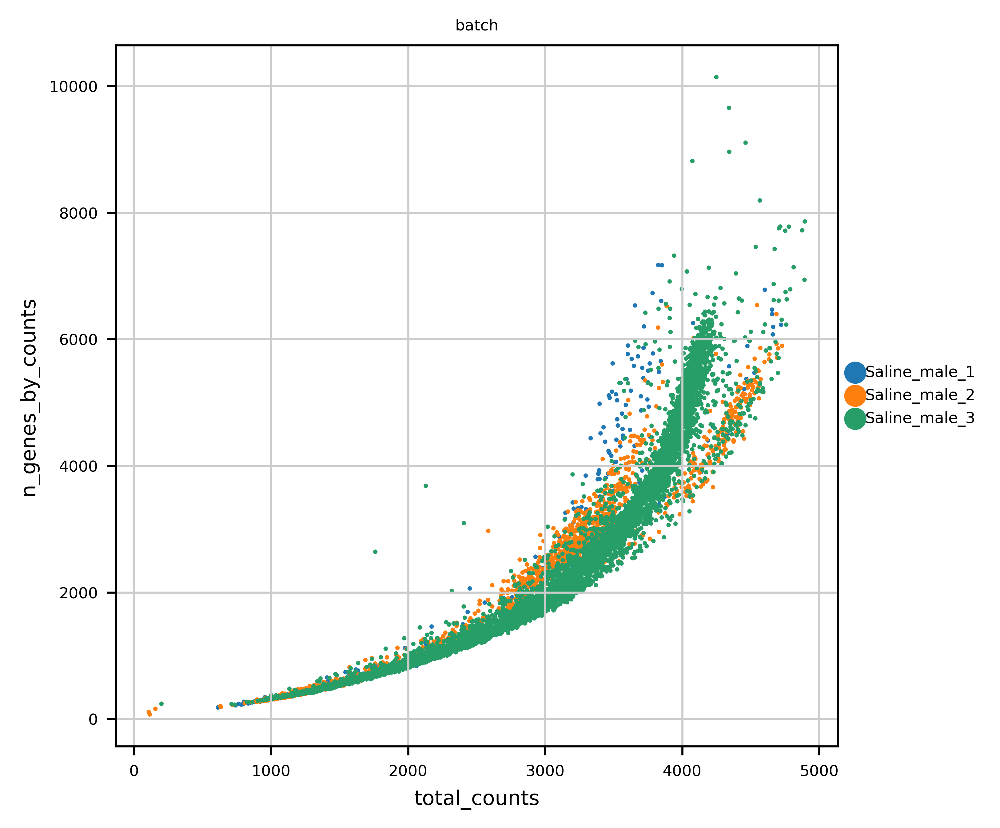

In [231]:
sc.pl.scatter(Saline, x='total_counts', y='n_genes_by_counts',color='batch')

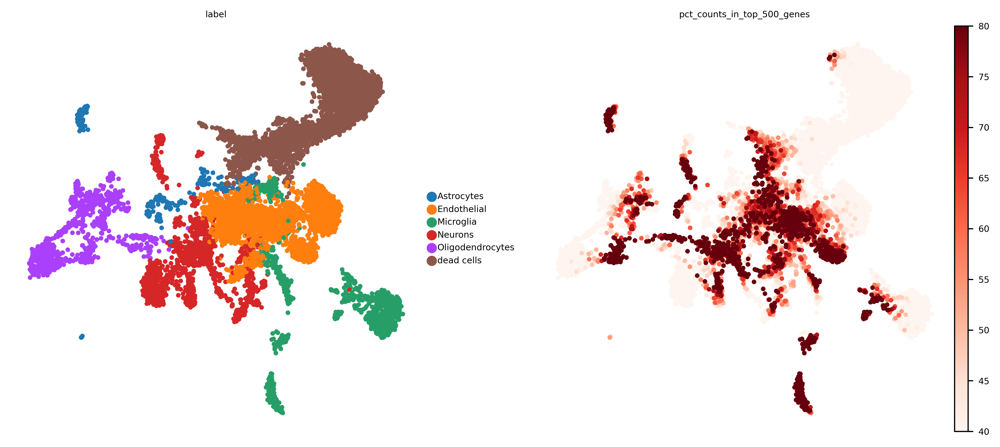

In [258]:
sc.pl.umap(
    Saline, 
    color=['label','pct_counts_in_top_500_genes'],
    # legend_fontsize='x-small',
    vmin=40,vmax=80,
    cmap='Reds', 
    # layer='scaled',
    size=40, hspace=2,
    # add_outline=.1
)

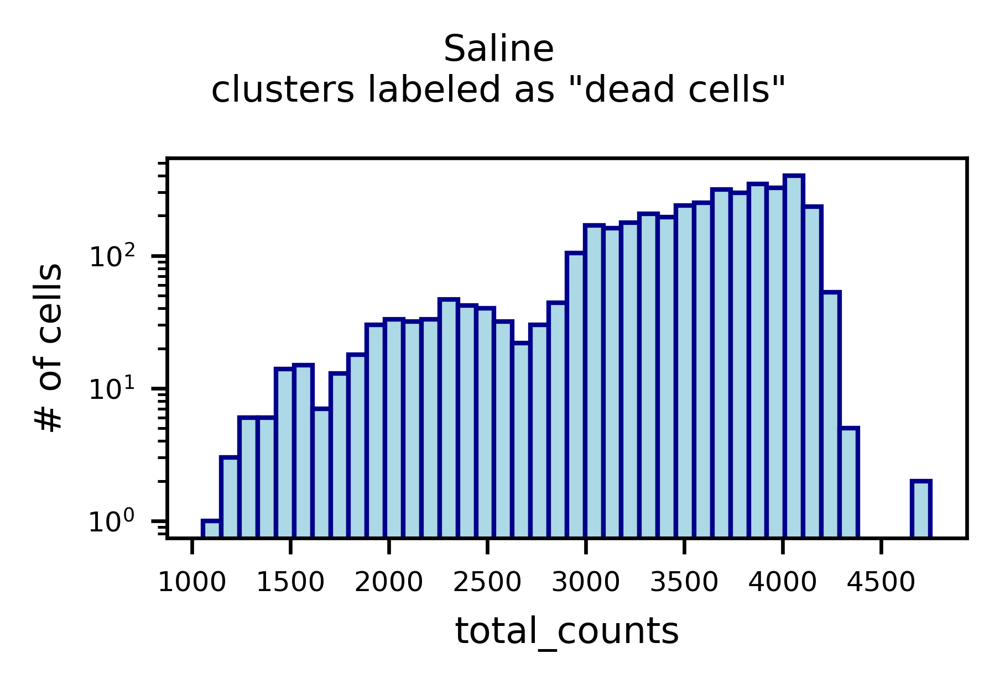

In [260]:
x_axis = 'total_counts'
plt.figure(figsize=(3,2))
plt.hist(
    Saline.obs[Saline.obs.label == 'dead cells'][x_axis], 
    bins=40, color = "lightblue", ec="darkblue")
plt.yscale("log")
plt.ylabel("# of cells")
plt.xlabel(x_axis)
# plt.axvline(x=Snap25_thr,color='r',alpha=0.50)
# plt.text(Snap25_thr + 0.2, 10**4, 'threshold={:.1f}'.format(Snap25_thr))
plt.suptitle('Saline\nclusters labeled as "dead cells"',fontsize=8)
plt.grid(b=None)
plt.tight_layout()
# plt.savefig('figures/Snap25_hist.pdf')
plt.show()

## 

In [188]:
def plot_Snap25(df,thr,condition):    
    plt.figure(figsize=(3,2))
    plt.hist(df,40,color = "lightblue", ec="darkblue")
    plt.yscale("log")
    plt.ylabel("# of cells")
    plt.xlabel("Expression (normalized)")
    plt.axvline(x=thr,color='r')
    plt.suptitle(f'{condition}\n' + '"Snap25" expression\nthreshold (85% quintile)={:.2f}'.format(thr),fontsize=8)
    plt.grid(b=None)
    plt.tight_layout()
    plt.show()

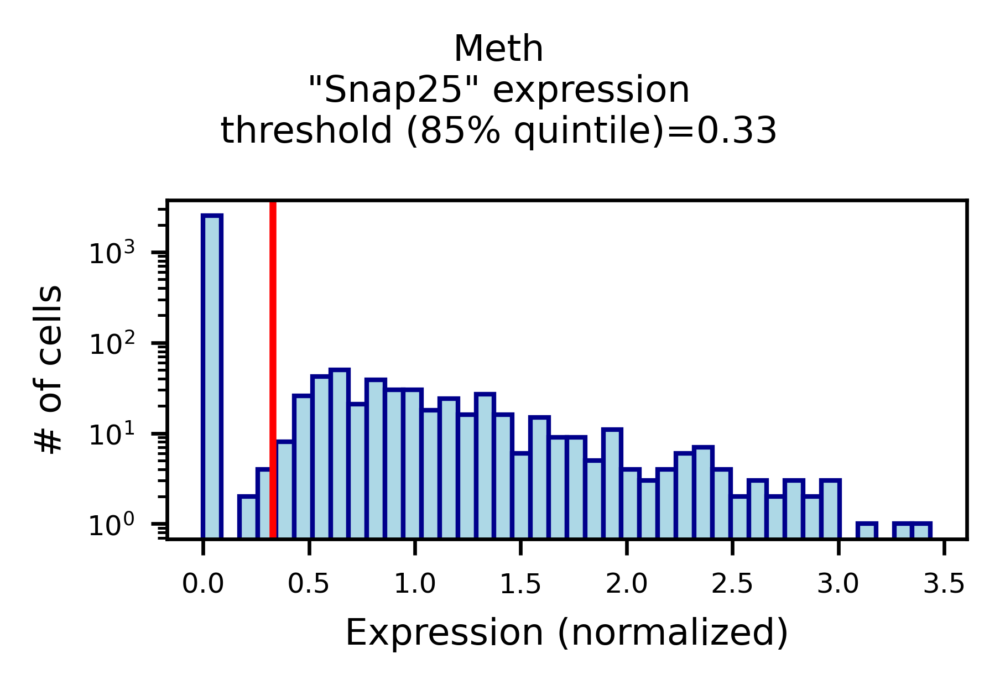

In [202]:
plot_Snap25(Meth_Snap25_df, Meth_Snap25_thr,'Meth')

## Save files

Write cluster annotated `adata` into files for all three conditions:

In [65]:
# Skip clusters labeled as dead cells
Saline_v2 = Saline[Saline.obs.label != 'dead cells'].copy()

Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


In [69]:
MDMA.write(
    'celltyping/MDMA-annotated.h5ad.gz',
    compression='gzip'
)

Meth.write(
    'celltyping/Meth-annotated.h5ad.gz',
    compression='gzip'
)
    
Saline_v2.write(
    'celltyping/Saline-annotated.h5ad.gz',
    compression='gzip'
)

# 

In [ ]:
# # scale and store results in layer
# adata.layers['scaled'] = sc.pp.scale(adata, copy=True).X

# ax = sc.pl.stacked_violin(
#     adata, neuron_genes, groupby='leiden', swap_axes=False, dendrogram=True,
#     colorbar_title='mean z-score', layer='scaled', vmin=-2, vmax=2, cmap='RdBu_r'
# )

In [ ]:
# sc.pl.umap(
#     adata, 
#     color=['batch','leiden'] + list(neuron_genes),
#     legend_fontsize='x-small',
#     # vmin=-2,vmax=2, cmap='bwr', 
#     layer='scaled',
#     size=40, hspace=2,
#     # save='tdT.pdf'
#     # add_outline=1
# )

# # !mv figures/umaptdT.pdf figures/tdT_umap_Meth.pdf

___

In [ ]:
writer = pd.ExcelWriter('celltyping/rank_genes.xlsx', engine='xlsxwriter')

# Write each dataframe to a different worksheet.
for c in set(adata.obs['cond']):
    rank_genes_to_df(eval(c),n=50).to_excel(writer,sheet_name=c)

# Close the Pandas Excel writer and output the Excel file.
writer.save()

## Integrating and Comparing Samples
- https://scanpy.readthedocs.io/en/stable/generated/scanpy.external.pp.harmony_integrate.html

> `harmony_integrate` function uses the python port of Harmony, [harmonypy](https://github.com/slowkow/harmonypy), to integrate single-cell data stored in an AnnData object. As Harmony works by **adjusting the principal components**, this function should be **run after performing PCA but before computing the neighbor graph**.

- https://scanpy.readthedocs.io/en/stable/generated/scanpy.external.pp.mnn_correct.html#scanpy.external.pp.mnn_correct


- https://github.com/JinmiaoChenLab/Batch-effect-removal-benchmarking

> Based on our results, Harmony, LIGER, and Seurat 3 are the recommended methods for batch integration. Due to its significantly shorter runtime, **Harmony** is recommended as the first method to try, with the other methods as viable alternatives.

<!-- Aidan's notes 
> The 4 strategies I will try are: 
> 1. No integration (just mergin all datasets together). This will give me a sense of the batch effect between samples
> 2. Seurat standard integration (using the anchro identification method)
> 3. Seurat scTransform (adjusts counts based on umi per cell)
> 4. Harmony

Try [harmonypy](https://anaconda.org/bioconda/harmonypy)

These are the critical R packages I used to write [this note](https://slowkow.com/notes/harmony-animation/):
- [MUDAN](https://github.com/jefworks/MUDAN) by Jean Fan
- [Harmony](https://github.com/immunogenomics/harmony) and [presto](https://github.com/immunogenomics/presto) by Ilya Korsunsky
- [gganimate](https://gganimate.com/) by Thomas Lin Pedersen -->

In [ ]:
# sc.pp.neighbors(mergedadata0, use_rep='X_pca')
# sc.tl.umap(mergedadata0)
# sc.tl.leiden(mergedadata0)

In [ ]:
# sc.tl.pca(mergedadata)
# sce.pp.harmony_integrate(mergedadata, 'batch')
# sc.pp.neighbors(mergedadata, use_rep='X_pca_harmony')
# sc.pp.neighbors(mergedadata, use_rep='X_pca')
# sc.tl.umap(mergedadata)
# sc.tl.leiden(mergedadata)

In [ ]:
# %%time 
# pdf_pages = PdfPages('figures/umap.pdf')

# # The PDF document
# for sample in data:
#     adata = data[sample].copy()

#     # Create a figure instance (ie. a new page)
#     fig = plot.figure(dpi=300)

#     # Plot whatever you wish to plot
#     print ('\033[1m' + sample)
#     fig = sc.pl.embedding(adata, basis='rna_umap',color=adata.obs.columns[2:], size=10,show=False,return_fig=True)
#     fig.suptitle(sample +'\n'+str(adata.shape[0])+' cells, '+str(adata.shape[1])+' genes', fontsize=20)
    
#     fig.set_size_inches(18.5, 10.5) # https://stackoverflow.com/questions/332289/how-do-you-change-the-size-of-figures-drawn-with-matplotlib
    
#     # Done with the page
#     pdf_pages.savefig(fig)
#     plt.close(fig)    
# #     del adata
    
# # Write the PDF document to the disk
# pdf_pages.close()

In [ ]:
# import altair as alt
# from functools import partial

# alt.renderers.enable("png")
# alt.data_transformers.disable_max_rows()

# def embedding_chart(df: pd.DataFrame, coord_pat: str, *, size=5) -> alt.Chart:
#     """Make schema for coordinates, like sc.pl.embedding."""
#     x, y = df.columns[df.columns.str.contains(coord_pat)]
#     return (
#         alt.Chart(plotdf, height=300, width=300)
#         .mark_circle(size=size)
#         .encode(
#             x=alt.X(x, axis=None),
#             y=alt.Y(y, axis=None),
#         )
#     )

# def umap_chart(df: pd.DataFrame, **kwargs) -> alt.Chart:
#     """Like sc.pl.umap, but just the coordinates."""
#     return embedding_chart(df, "umap", **kwargs)

# def encode_color(c: alt.Chart, col: str, *, qdomain=(0, 1), scheme: str = "lightgreyred") -> alt.Chart:
#     """Add colors to an embedding plot schema."""
#     base = c.properties(title=col)
#     if pd.api.types.is_categorical(c.data[col]):
#         return base.encode(color=col)
#     else:
#         return base.encode(
#             color=alt.Color(
#                 col,
#                 scale=alt.Scale(
#                     scheme=scheme,
#                     clamp=True,
#                     domain=list(c.data[col].quantile(qdomain)),
#                     nice=True,
#                 )
#             )
#         )
#     plotdf = sc.get.obs_df(
#         rna,
#         obsm_keys=[("X_umap", i) for i in range(2)] + [("protein", i) for i in rna.obsm["protein"].columns]
#     )

#     fig = (
#         alt.concat(
#             *map(partial(encode_color, umap_chart(plotdf), qdomain=(0, .95)), plotdf.columns[3:]),
#             columns=2
#         )
#         .resolve_scale(color='independent')
#         .configure_axis(grid=True)
#     )

In [ ]:
# def preprocessing(adata):
#     # Basic filtering:
#     sc.pp.filter_genes(adata, min_cells=10)
#     sc.pp.filter_cells(adata, min_genes=150)
#     # annotate the group of mitochondrial genes as 'mt'
#     adata.var['mt'] = adata.var.index.str.startswith('MT-')  
#     # Remove cells that have too many mitochondrial genes expressed or too many total counts:
#     sc.pp.calculate_qc_metrics(adata, qc_vars=['mt'], percent_top=None, log1p=False, inplace=True)
#     adata = adata[adata.obs.n_genes_by_counts < 2500, :]
#     adata = adata[adata.obs.pct_counts_mt < 5, :]
#     # Total-count normalize (library-size correct) the data matrix 
#     # 𝐗 to 10,000 reads per cell, so that counts become comparable among cells.
#     sc.pp.normalize_per_cell(adata)
#     # Logarithmize the data:
#     sc.pp.log1p(adata)
#     # Identify highly-variable genes.
#     sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
#     adata.raw = adata
#     # Actually do the filtering
#     adata = adata[:, adata.var.highly_variable]
#     # Regress out effects of total counts per cell and the percentage of mitochondrial genes expressed. 
#     # Scale the data to unit variance.
#     sc.pp.regress_out(adata, ['total_counts', 'pct_counts_mt'])
#     # Scale each gene to unit variance. Clip values exceeding standard deviation 10.
#     sc.pp.scale(adata, max_value=10)

In [1]:
!conda env export --from-history

name: sc-analysis
channels:
  - anaconda
  - r
  - conda-forge
  - bioconda
dependencies:
  - scanpy
  - scvi-tools
  - scrublet
  - leidenalg
  - cellrank
  - xlsxwriter
  - tensorflow
prefix: /data_gilbert/home/aarab/anaconda3/envs/sc-analysis
